# Intensity self-imaging with a line grating
**H. Hamam**

This numerical pilot uses the vector Galerkin model of a zero-thickness, perfectly conducting periodic screen at normal incidence. The fixed period is 2.53 wavelengths. The target is to reproduce the unpolarized electric intensity and normal flux between two downstream planes while keeping the propagating modes distinct under every lateral shift. TE and TM are averaged incoherently with equal weights. The comparison uses the original scales without rescaling each plane. Electric intensity is the sum of the squared electric components. Normal flux is an energy-crossing observable. A real near-field detector needs its own measurement model.

For the analytical control, the prescribed mode u = A + B cos(2πx/d) exp(−2πiz/L) has identical intensity at L/6 and 5L/6 for real A and B. The two side orders require the same relative phase factor exp(2πi/3) to match, whereas a translation applies reciprocal factors. Thus no global phase and translation map the complex fields. The physical slit synthesis below tests approximate recurrence with all retained harmonics.


In [1]:
from pathlib import Path
import json
from time import perf_counter
import numpy as np
from scipy.special import jv
from scipy.optimize import differential_evolution, minimize
import matplotlib.pyplot as plt
K=2*np.pi
trapz=getattr(np,'trapezoid',None) or np.trapz


## Vector forward solver
Reproduced from Quantum_Field_Diffraction_Gratings_and_Design.ipynb.

In [2]:
def _orders(d, Q):
    M = int(np.ceil(Q*d/(2*np.pi))); m = np.arange(-M, M+1); q = 2*np.pi*m/d
    kz = np.sqrt((K**2-q**2).astype(complex)); kz = np.where(kz.imag < 0, -kz, kz)
    return m, q, kz

def solve_periodic(d, slits, pol, extra=0, xi_scale=1.0):
    # Exact mode function for a screen of period d with slits = [(centre, width), ...] in each period.
    nb = [int(K*w/2)+8+extra for _, w in slits]                               # basis functions per slit
    Q = max(4*K, max(2*xi_scale*max(400.0, 0.6*n*n)/w for n, (_, w) in zip(nb, slits)))
    m, q, kz = _orders(d, Q); rows, meta = [], []
    for s, ((xc, w), n_s) in enumerate(zip(slits, nb)):
        xi = q*w/2; xis = np.where(xi == 0, 1.0, xi); ph = np.exp(-1j*q*xc)
        for n in range(n_s):
            f = (w/2)*np.pi*(n+1)*(-1j)**n*np.where(xi == 0, 0.5*(n == 0), jv(n+1, xis)/xis) if pol == "TE" else (w/2)*np.pi*(-1j)**n*jv(n, xi)
            rows.append(ph*f); meta.append((s, n, w))
    Phi = np.array(rows); A = (np.conj(Phi)*(kz if pol == "TE" else 1/(1j*kz)))@Phi.T/d
    q_end = q[-1]+np.pi/d                                                     # analytic remainder of the order sum
    for a, (sa, na, wa) in enumerate(meta):
        for b, (sb, nb_, wb) in enumerate(meta):
            if sa == sb and (na-nb_) % 2 == 0:
                A[a, b] += 1j*(na+1)*(nb_+1)/(q_end*wa/2) if pol == "TE" else -wa/(2*q_end)
    i0 = len(m)//2; c = np.linalg.solve(A, np.conj(Phi[:, i0])*(K if pol == "TE" else 1.0))
    S = c@Phi; S = S if pol == "TE" else S/(1j*kz)
    prop = np.abs(q) < K; d0 = (m == 0).astype(float); r = (-d0+S/d) if pol == "TE" else (d0-S/d)
    PT = np.where(prop, kz.real*np.abs(S)**2/(K*d*d), 0.0); PR = np.where(prop, kz.real*np.abs(r)**2/K, 0.0)
    return {"d": d, "pol": pol, "m": m, "q": q, "kz": kz, "S": S, "PT": PT, "PR": PR, "T": float(PT.sum()), "R": float(PR.sum()), "unknowns": len(c), "flux": True}

def scalar_periodic(d, slits, model="exact", M=6000):
    # Scalar Kirchhoff element with exact ('exact') or Fresnel ('fresnel') propagation.
    m = np.arange(-M, M+1); q = 2*np.pi*m/d
    S = sum(np.exp(-1j*q*xc)*w*np.sinc(q*w/(2*np.pi)) for xc, w in slits)+0j
    if model == "exact":
        kz = np.sqrt((K**2-q**2).astype(complex)); kz = np.where(kz.imag < 0, -kz, kz)
        PT = np.where(np.abs(q) < K, kz.real*np.abs(S)**2/(K*d*d), 0.0)
    else:
        kz = (K-q**2/(2*K)).astype(complex); PT = np.abs(S)**2/(d*d)
    return {"d": d, "pol": model, "m": m, "q": q, "kz": kz, "S": S, "PT": PT, "T": float(PT.sum()), "flux": model == "exact"}

def field(sol, x, z, derivative=False):
    f = sol["S"]*np.exp(1j*sol["kz"]*z)*(1j*sol["kz"] if derivative else 1)
    keep = np.abs(f) > 1e-14*np.abs(f).max()
    return np.exp(1j*np.outer(np.atleast_1d(x), sol["q"][keep]))@f[keep]/sol["d"]

def detection_density(sol, x, z):
    # Probability per unit length that the photon is detected at (x, z), times the period d.
    u = field(sol, x, z)
    return np.imag(np.conj(u)*field(sol, x, z, True))/K if sol["flux"] else np.abs(u)**2

def strip_probability(sol, z, x0=0.0, half_width=0.5, n=81):
    x = np.linspace(x0-half_width, x0+half_width, n)
    return float(trapz(detection_density(sol, x, z), x)/sol["d"])
order = lambda sol, j: float(sol["PT"][len(sol["m"])//2+j])
print("Solver ready.")

Solver ready.


## Geometry search
One-, two- and three-slit mirror-symmetric unit cells are searched with differential evolution and Powell refinement. Slit widths and periodic metal gaps are at least 0.15 wavelength. The two planes are searched in [1.5, 4] and [8, 12] wavelengths. The search minimizes the larger of the relative L2 electric-intensity and flux errors, with soft penalties for low contrast, low target throughput, negligible participation of a target order, or high shift-optimized mode overlap. Equal order splitting is tracked separately. Search profiles use propagating orders and the forward solve includes evanescent orders.


In [3]:
d=2.53
minimum=.15
L=1/(1-np.sqrt(1-d**-2))
x=np.linspace(-d/2,d/2,256,endpoint=False)
m=np.arange(-2,3)
phase=np.exp(1j*np.outer(x,2*np.pi*m/d))
kz=K*np.sqrt(1-(m/d)**2)
shift=np.linspace(0,d,513)
shift_phase=np.exp(1j*np.outer(m,2*np.pi*shift/d))
def geometry(v, topology):
    # Allocate remaining half-cell length to segments above their hard minima.
    thresholds={1:[minimum/2,minimum/2],2:[minimum/2,minimum,minimum/2],3:[minimum/2,minimum,minimum,minimum/2]}[topology]
    lengths=np.array(thresholds)+(d/2-sum(thresholds))*v[:topology+1]/sum(v[:topology+1])
    if topology==1:
        return [(0.,2*lengths[0])]
    w=lengths[-2]
    c=sum(lengths[:-2])+w/2
    return [(-c,w)]+([(0.,2*lengths[0])] if topology==3 else [])+[(c,w)]
def trace(coeff,z):
    waves=coeff*np.exp(1j*kz*z)
    u=phase@waves
    return np.real(np.conj(u)*(phase@(kz*waves)))/K
def evaluate(v, topology, extra=0, xi_scale=1.):
    slits=geometry(v,topology)
    z1,z2=v[-2:]
    records=[]
    electric=[]
    for pol in ('TE','TM'):
        sol=solve_periodic(d,slits,pol,extra=extra,xi_scale=xi_scale)
        rows=np.isin(sol['m'],m)
        coeff=sol['S'][rows]/d
        pt=sol['PT'][rows]
        f1,f2=trace(coeff,z1),trace(coeff,z2)
        def electric_at(z):
            a=coeff*np.exp(1j*kz*z)
            if pol=='TE':
                return abs(phase@a)**2
            return abs(phase@(a*kz/K))**2+abs(phase@(a*m/d))**2
        electric.append([electric_at(z1),electric_at(z2)])
        delta=z2-z1
        overlap=float(np.max(np.abs((pt*np.exp(1j*kz*delta))@shift_phase)**2)/sol['T']**2)
        records.append((sol,pt,f1,f2,overlap))
    p=(records[0][1]+records[1][1])/2
    f1=(records[0][2]+records[1][2])/2
    f2=(records[0][3]+records[1][3])/2
    e1,e2=np.mean(electric,axis=0)
    error=max(np.linalg.norm(f2-f1)/np.linalg.norm(f1),
              np.linalg.norm(e2-e1)/np.linalg.norm(e1))
    balance=max(abs(p[1:4]/p[1:4].mean()-1))
    contrast=np.std(f1)/np.mean(f1)
    return error,balance,contrast,p,records
def loss(v,topology):
    err,bal,contrast,p,r=evaluate(v,topology)
    # Balance is reported separately. Penalize a flat profile or a near field copy.
    return err+2*max(0,max(rr[-1] for rr in r)-.85)+max(0,.12-contrast)+max(0,.12-p[1:4].sum())+2*max(0,.10-min(p[1:4])/p[1:4].sum())
def run():
    report=[]
    for topology in (1,2,3):
        bounds=[(.02,1)]*(topology+1)+[(1.5,4),(8,12)]
        def log(v,convergence):
            if de_counter[0]%10==0: print(f'{topology} slits, generation {de_counter[0]}, score {loss(v,topology):.4g}',flush=True)
            de_counter[0]+=1
        de_counter=[1]
        fit=differential_evolution(loss,bounds,args=(topology,),popsize=7,maxiter=30,seed=82+topology,callback=log,polish=False)
        local=minimize(loss,fit.x,args=(topology,),method='Powell',bounds=bounds,options={'maxiter':40,'xtol':1e-7,'ftol':1e-8})
        v=min([fit.x,local.x],key=lambda v:loss(v,topology))
        err,bal,contrast,p,r=evaluate(v,topology,4,2)
        print(topology,v,geometry(v,topology),err,bal,contrast,p,[rr[-1] for rr in r],flush=True)
        report.append({'topology':topology,'parameters':v.tolist(),'score':float(loss(v,topology))})
    return report


In [4]:
# Set True to repeat the optimization.
RERUN_SEARCH=False
recorded_candidates=[{'topology': 1, 'parameters': [0.1353535043425313, 0.08917148995413461, 1.510353388240782, 11.119093562325679], 'score': 0.033333702357732475}, {'topology': 2, 'parameters': [0.9161238077137659, 0.5788272002512641, 0.2808453404366267, 1.5275535604333503, 11.236883834133499], 'score': 0.020934602439432192}, {'topology': 3, 'parameters': [0.20554660341908582, 0.3475640625481641, 0.240881019864722, 0.7686249033299994, 1.6774382388760516, 10.929479746603207], 'score': 0.0265489577566181}]
print("Searching geometries." if RERUN_SEARCH else "Using recorded candidates.")
candidates=run() if RERUN_SEARCH else recorded_candidates


Using recorded candidates.


## Verification with the retained evanescent spectrum
The complex-mode overlap is computed for the propagating output, using flux-normalized amplitudes. Symmetry reduces the squared overlap to a quartic in cos(2πa/d). Evaluating its stationary points and endpoints maximizes it over all lateral shifts. Profile discrepancies below use the full retained spectrum. The relative L2 error is the norm of the difference divided by the norm at the first plane.

In [5]:
from numpy.polynomial import Polynomial
from scipy.optimize import minimize
def validate(v,topology,extra=4,xi_scale=2.):
    z1,z2=v[-2:]
    rows={}
    flux_profiles=[]
    electric_profiles=[]
    for pol in ('TE','TM'):
        sol=solve_periodic(d,geometry(v,topology),pol,extra=extra,xi_scale=xi_scale)
        keep=np.isin(sol['m'],m)
        pt,pr=sol['PT'][keep],sol['PR'][keep]
        weights=pt*np.exp(1j*kz*(z2-z1))/sol['T']
        # For a symmetric cell the shift overlap reduces to a quadratic in cos(2πa/d).
        poly=Polynomial([weights[2]-weights[0]-weights[4],weights[1]+weights[3],2*(weights[0]+weights[4])])
        sq=poly*Polynomial(poly.coef.conj())
        roots=sq.deriv().coef.real
        stationary=Polynomial(roots).roots()
        args=[-1.,1.]+[float(a.real) for a in stationary if abs(a.imag)<1e-9 and -1<a.real<1]
        overlap=float(max(sq(a).real for a in args))
        fs=[]; es=[]; prop=[]; amp_error=[]
        for z in (z1,z2):
            full=field(sol,x,z)
            fs.append(detection_density(sol,x,z))
            coeff=sol['S'][keep]/d
            prop.append(trace(coeff,z))
            amp_error.append(float(np.linalg.norm(full-phase@(coeff*np.exp(1j*kz*z)))/np.linalg.norm(full)))
            if pol=='TE': es.append(abs(full)**2)
            else:
                modal=sol['S']*np.exp(1j*sol['kz']*z)/d
                relevant=abs(modal)>1e-14*abs(modal).max()
                plane=np.exp(1j*np.outer(x,sol['q'][relevant]))
                es.append(abs(plane@(modal[relevant]*sol['kz'][relevant]/K))**2+
                          abs(plane@(modal[relevant]*sol['q'][relevant]/K))**2)
        metric=lambda a: float(np.linalg.norm(a[1]-a[0])/np.linalg.norm(a[0]))
        flux_profiles.append(np.array(fs));electric_profiles.append(np.array(es))
        rows[pol]={'PT':pt.tolist(),'PR':pr.tolist(),'T':sol['T'],'R':sol['R'],
                   'max_shift_overlap_squared':overlap,'relative_flux_error':metric(fs),
                   'relative_electric_intensity_error':metric(es),
                   'relative_evanescent_amplitude':amp_error,
                   'relative_flux_evanescent_change':[float(np.linalg.norm(f-p)/np.linalg.norm(f)) for f,p in zip(fs,prop)]}
    error,balance,contrast,p,_=evaluate(v,topology,extra,xi_scale)
    candidates={'slits':geometry(v,topology),'planes':[z1,z2],'TE_TM':rows,'PT_unpolarized':p.tolist(),
                'unpolarized_flux_error':metric(np.mean(flux_profiles,axis=0)),
                'unpolarized_electric_intensity_error':metric(np.mean(electric_profiles,axis=0)),
                'unpolarized_target_throughput':float(sum(p[1:4])), 'target_balance_error':float(balance),
                'unpolarized_flux_contrast':float(contrast)}
    return candidates,np.mean(flux_profiles,axis=0),np.mean(electric_profiles,axis=0)


In [6]:

print("Checking the analytical three-order control.")
u1=1+.7*np.cos(2*np.pi*x/d)*np.exp(-1j*np.pi/3)
u2=1+.7*np.cos(2*np.pi*x/d)*np.exp(+1j*np.pi/3)
assert np.allclose(abs(u1)**2,abs(u2)**2,rtol=0,atol=2e-15)
def discrepancy(report):
    return max(report['unpolarized_flux_error'],report['unpolarized_electric_intensity_error'])
verified=[]
for candidate in candidates:
    topology=candidate['topology']
    parameters=np.array(candidate['parameters'])
    print(f"Refining {topology}-slit topology.")
    report,_,_=validate(parameters,topology)
    refined,flux,electric=validate(parameters,topology,extra=8,xi_scale=3)
    refined['topology']=topology
    refined['refinement_max_order_probability_change']=max(abs(a-b) for pol in ('TE','TM') for key in ('PT','PR') for a,b in zip(report['TE_TM'][pol][key],refined['TE_TM'][pol][key]))
    refined['refinement_profile_metric_change']=abs(discrepancy(refined)-discrepancy(report))
    print(f"Flux error {refined['unpolarized_flux_error']:.4%} | electric error {refined['unpolarized_electric_intensity_error']:.4%}")
    verified.append((refined,flux,electric))
final,flux,electric=min(verified,key=lambda item:discrepancy(item[0]))
final['peak_normalized_max_flux_difference']=float(np.max(abs(flux[1]-flux[0]))/np.max(abs(flux[0])))
final['peak_normalized_max_electric_difference']=float(np.max(abs(electric[1]-electric[0]))/np.max(abs(electric[0])))
assert all(abs(v['T']+v['R']-1)<1e-10 for v in final['TE_TM'].values())
print(json.dumps(final,indent=2))


Checking the analytical three-order control.
Refining 1-slit topology.
Flux error 3.3482% | electric error 3.2832%
Refining 2-slit topology.
Flux error 1.9729% | electric error 2.1111%
Refining 3-slit topology.
Flux error 2.6534% | electric error 2.6039%
{
  "slits": [
    [
      -0.8051109307168646,
      0.4645452172740534
    ],
    [
      0.8051109307168646,
      0.4645452172740534
    ]
  ],
  "planes": [
    1.5275535604333503,
    11.236883834133499
  ],
  "TE_TM": {
    "TE": {
      "PT": [
        0.049056713200377154,
        0.03536095658807263,
        0.24927799753100766,
        0.035360956588072846,
        0.04905671320037701
      ],
      "PR": [
        0.04905671320037715,
        0.03536095658807263,
        0.4130513233151936,
        0.035360956588072846,
        0.04905671320037701
      ],
      "T": 0.41811333710790727,
      "R": 0.5818866628920933,
      "max_shift_overlap_squared": 0.5908984854868284,
      "relative_flux_error": 0.14256210787527457,
  

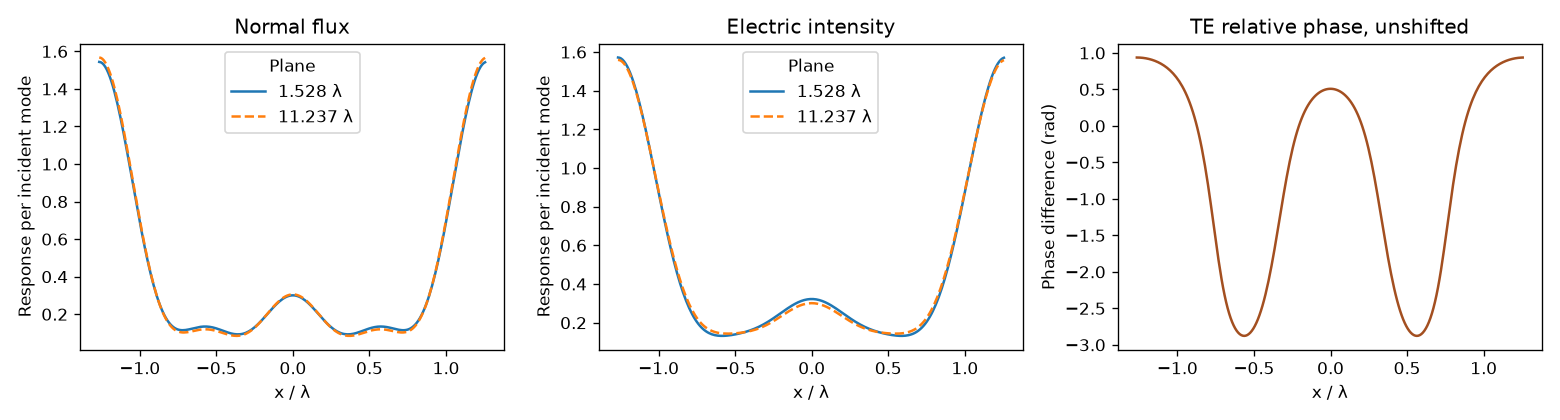

In [7]:

fig,axes=plt.subplots(1,3,figsize=(13,3.5))
for ax,pair,title in zip(axes,(flux,electric),('Normal flux','Electric intensity')):
    for i,(trace_i,style) in enumerate(zip(pair,('-','--'))):
        ax.plot(x,trace_i,style,label=f"{final['planes'][i]:.3f} λ")
    ax.set(xlabel='x / λ',ylabel='Response per incident mode',title=title)
    ax.legend(title='Plane')
sol=solve_periodic(d,final['slits'],'TE',extra=8,xi_scale=3)
z1,z2=final['planes']
a1,a2=field(sol,x,z1),field(sol,x,z2)
phase_difference=np.angle(a2*np.conj(a1)*np.exp(-1j*K*(z2-z1)))
phase_difference[abs(a1*a2)<1e-10]=np.nan
axes[2].plot(x,phase_difference,color='#a34f20')
axes[2].set(xlabel='x / λ',ylabel='Phase difference (rad)',title='TE relative phase, unshifted')
fig.tight_layout()


In [ ]:

print("Saving numerical summaries.")
try:
    from google.colab import drive
except ImportError:
    output_dir=Path('outputs')/'Quantum_Field_Diffraction'
else:
    drive.mount('/content/drive')
    output_dir=Path('/content/drive/MyDrive/Outputs/Quantum_Field_Diffraction')
output_dir.mkdir(parents=True,exist_ok=True)
result_path=output_dir/'intensity_self_imaging.json'
result_path.write_text(json.dumps({'period_lambda':d,'best':final,'candidates':[v[0] for v in verified]},indent=2))
print(result_path)
